# Agentic Statistical Analysis Assistant — Python v2
**Jingcheng Zhou and Junliang Lyu · Module 6: Visualize Your Multi-Agent LangGraph**

This notebook compiles, visualizes and runs one real **17-node LangGraph StateGraph**.
Model A plans and explains; a different Model B reviews. Python/SciPy performs all v2
statistics and deterministic data checks. No R installation is needed for v2.
All example datasets are **synthetic**. Results are computed when cells run.

Run from this project folder after `pip install -r requirements.txt`. Configure `.env`
from `.env.example`: `LLM_MODE=real` uses two distinct local Ollama models; `mock` uses
explicitly labelled rule-based stand-ins to test orchestration. `auto` selects real when
configuration is available, otherwise mock. No fine-tuning or model training occurs.
The saved outputs state the actual mode. Human evaluation of report quality remains a
separate benchmark activity; these smoke examples are not an accuracy estimate.

In [1]:
import os, sys, json, inspect
from pathlib import Path
from IPython.display import Image, Markdown, display

PROJECT = next((candidate for candidate in (Path.cwd(), *Path.cwd().parents)
                if (candidate / "stat_assistant").is_dir()), None)
if PROJECT is None:
    raise RuntimeError("Start Jupyter from within the project repository.")
sys.path.insert(0, str(PROJECT))
from stat_assistant.models import create_agents
from stat_assistant.workflow import build_graph
from stat_assistant.runtime import new_run, ask_followup, resume_answers, collect_answers
from stat_assistant.settings import DATA_DIR, OUTPUT_DIR
from stat_assistant.nodes import AnalysisState
import stat_assistant.workflow as graph_module

agent_a, agent_b, configuration = create_agents()
graph = build_graph(agent_a, agent_b, mode=configuration["mode"])
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(json.dumps(configuration, indent=2))
print("REAL LLM calls" if configuration["mode"] == "real" else "MOCK stand-ins; no LLM calls")
print("All statistical calculations use Python/SciPy.")

{
  "mode": "mock",
  "model_a": "ollama:qwen3:8b",
  "model_b": "ollama:gemma3:12b"
}
MOCK stand-ins; no LLM calls
All statistical calculations use Python/SciPy.


## State, routers and graph construction
The source below is imported from the package used by these examples. `errors`, `trace`
and `model_calls` use append reducers and a request number. Other fields store the plan,
data version, diagnostics, protected numerical results, draft, review and session memory.
Every node has an explicit role; every conditional edge has a labelled path map.

In [2]:
for obj in (AnalysisState, graph_module.entry_route, graph_module.plan_route,
            graph_module.diagnostic_route, graph_module.correction_route,
            graph_module.review_route, graph_module.followup_route, build_graph):
    print(inspect.getsource(obj))

class AnalysisState(TypedDict, total=False):
    run_id: str
    request_number: int
    request_kind: str
    research_question: str
    followup_question: str
    followup_focus: str
    followup_route: str
    design_info: dict
    original_data_path: str
    data_path: str
    data_version: str
    data_fingerprint: str
    followup_data_changed: bool
    followup_design_changed: bool
    followup_dataset_replaced: bool
    analysis_plan: dict
    plan_feedback: list
    plan_revision_count: int
    plan_route: str
    data_summary: dict
    llm_diagnostics: dict
    stat_diagnostics: dict
    diagnostic_route: str
    diagnostic_assessment: dict
    stop_reasons: list
    clarification_requests: list
    clarification_answers: list
    clarification_rounds: int
    rejected_answers: list
    excluded_ids: list
    verified_ids: list
    correction_log: list
    user_requested_stop: bool
    conf_level: float
    stat_result: dict
    stats_block: dict
    report_draft: dict
    re

## Diagram rendered from the compiled graph
The `graph` object below is also used by every example. Rendering uses LangGraph's
`draw_mermaid_png()` and the Mermaid rendering service; this cell needs internet access.

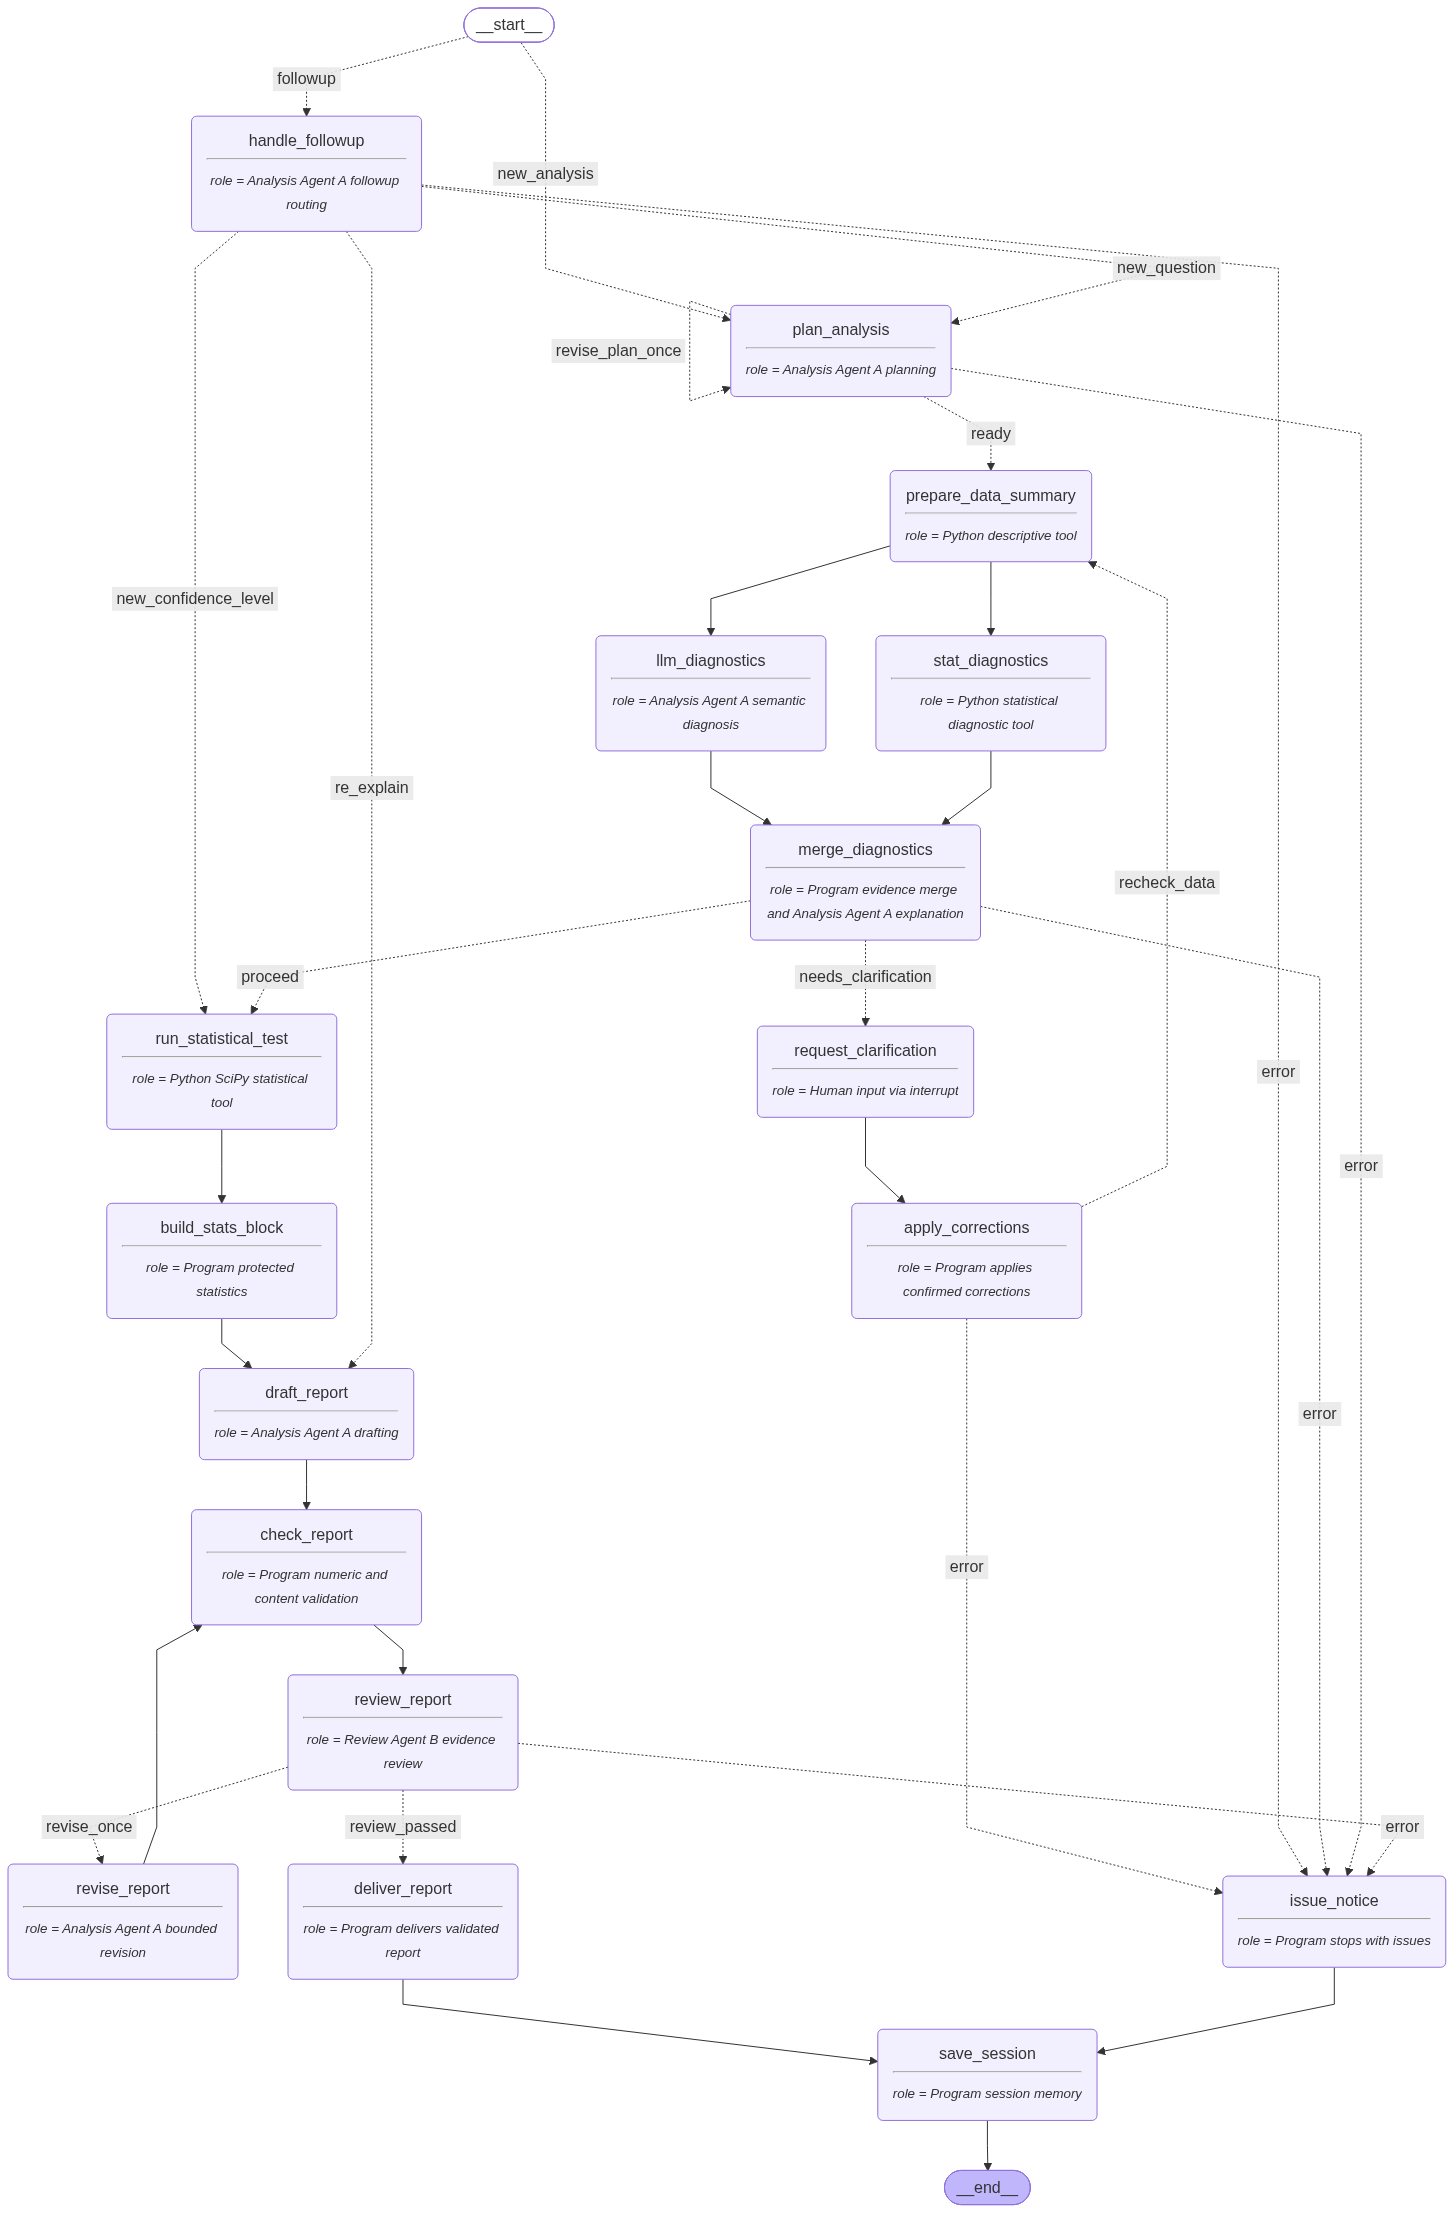

In [3]:
png_bytes = graph.get_graph().draw_mermaid_png()
artifact_dir = PROJECT / "artifacts"
artifact_dir.mkdir(parents=True, exist_ok=True)
(artifact_dir / "graph.png").write_bytes(png_bytes)
(artifact_dir / "graph.mmd").write_text(graph.get_graph().draw_mermaid(), encoding="utf-8")
display(Image(png_bytes))

### What each node represents
| Step | Node | Actor and concrete output |
|---|---|---|
| Step 1 | `plan_analysis` | Model A maps the question and user-supplied variable meanings to one of four methods, roles, estimand, H0 and H1. The program checks roles and scope. |
| Step 2 | `prepare_data_summary` | Python reads the raw CSV, preserves missing entries and labels, and produces the shared descriptive summary. |
| Step 3 | `llm_diagnostics` | Model A reviews the summary, variable meanings, study design and goal alignment, with evidence for each concern. |
| Step 4 | `stat_diagnostics` | Python independently checks missing/nonfinite values, stated ranges and labels, duplicate IDs, sample size, degenerate variables, boxplot flags and method-specific conditions. Accepted OLS fits also receive Cook's distance, leverage and Koenker Breusch–Pagan diagnostics; flags require interpretation limitations, not automatic deletion. |
| Step 5 | `merge_diagnostics` | Fixed rules combine both branches and select proceed, clarification or stop; Model A explains that decision and phrases questions. |
| Step 6 | `request_clarification` | LangGraph `interrupt()` pauses and presents each flagged record and allowed actions to the user. |
| Step 7 | `apply_corrections` | Python validates explicit permitted actions and replacement values; source/reason notes are optional. It writes a new data version for approved changes and logs actions, affected cells/records, old/new values and any supplied notes. The original CSV stays unchanged; omitted notes remain empty. |
| Step 8 | `run_statistical_test` | Python/SciPy computes the planned test, estimate, p-value and interval where implemented. |
| Step 9 | `build_stats_block` | Python formats protected numeric fields, H0/H1, decision at alpha and required limitations. |
| Step 10 | `draft_report` | Model A receives the plan and evidence and writes an interpretation using numeric placeholders. |
| Step 11 | `check_report` | Python checks placeholders, mandatory fields, literal numbers, common label/value swaps, declared direction, decision and required limitation IDs. |
| Step 12 | `review_report` | Different Model B independently checks the rendered draft against the original statistical/design evidence. Critical issues fail review. |
| Step 13 | `revise_report` | Model A receives B's specific critical comments and program-check failures and makes at most one revision. |
| Step 14 | `deliver_report` | Python presents a report only after both the program check and B's review pass. |
| Step 15 | `issue_notice` | Python explains why no validated inferential report was delivered. |
| Step 16 | `save_session` | The graph saves the latest successful analysis for follow-ups in this thread. Memory is in-process, not a persistent production database. |
| Step 17 | `handle_followup` | Model A classifies a follow-up; the program verifies reuse conditions and routes it. |

### What the edges and conditions mean
LangGraph merges routes that have the same source and destination in its rendering. Such
an edge may show only `error`; the full path maps above and conditions below also include
unsupported requests, user stops and exhausted revisions that share that destination.

- **START** routes `new_analysis` to planning and `followup` to follow-up handling.
- Planning routes `ready` to summary, `revise_plan_once` back to itself, or `stop`/`error` to the issue notice. One plan revision is allowed.
- Summary fans out to **LLM diagnostics and Python diagnostics concurrently**. A join edge waits for **both** before merging; neither branch reads the other's draft findings.
- Merge routes `proceed` to the statistical test, `needs_clarification` to the interrupt, or `stop`/`error` to the issue notice. A failed assumption never starts an unlimited method search.
- Clarification proceeds to applying answers. Valid answers route `recheck_data` back to summary; user stop or errors go to the issue notice. At most two answered diagnostic rounds are allowed. Invalid input is re-asked and never applied.
- Test → protected statistics → draft → program check → Model B review passes the outputs along in order.
- Review routes `review_passed` to delivery, `revise_once` to revision → program check → review, or `fail_after_revision`/`error` to the issue notice.
- Follow-up routes `new_confidence_level` to recomputation, `re_explain` to a new draft, `new_question` to fresh planning and diagnostics, or `stop`/`error` to the issue notice. A changed dataset or study-design description triggers fresh checks.
- Delivery and issue notice both go to save-session → END. A per-request model-call cap and guarded exceptions prevent uncontrolled retries; interruption is deliberately re-raised so LangGraph can pause.

### Actual handoffs and prompting
**A → B** occurs when `draft_report` passes Model A's draft through `check_report` to
`review_report`. B sees the rendered draft **and independent original evidence**, including
statistics, design and correction history. **B → A** occurs on `revise_once`: B's critical
sentences and proposed fixes become inputs to `revise_report`.
These are two different models, configured separately. Python tools and the human-input step
are not extra LLM agents.

Model A uses schema-constrained structured output; planning uses one-shot prompting
with a concrete example. Diagnosis and review use explicit evidence and a
rubric; revision is a bounded reflection step. The system does not require or expose hidden
chain-of-thought. Python tools execute the structured plan rather than arbitrary generated code.
Two models reduce one source of correlated error but do not guarantee a correct interpretation.

In [4]:
TUTORING_DESIGN = {
    "id_column": "student_id", "randomized": False,
    "assignment": "Tutoring was voluntary and not randomized.",
    "independence": "Independent observations stated by the user; one record per independently sampled student.",
    "variables": {
        "tutoring": {"type": "categorical", "levels": ["yes", "no"], "meaning": "Attended tutoring"},
        "score": {"type": "numeric", "range": [0, 100], "meaning": "Exam score in points"},
    },
    "typical_outcome": "score",
}
STUDENT_DESIGN = {**TUTORING_DESIGN, "variables": {
    **TUTORING_DESIGN["variables"],
    "study_hours": {"type": "numeric", "range": [0, 24], "meaning": "Weekly study hours"},
    "passed": {"type": "categorical", "levels": ["yes", "no"], "meaning": "Passed the exam"},
}}
case_outputs = {}

def show_case(name, state):
    paused = bool(state.get("__interrupt__"))
    status = "paused_for_user" if paused else state.get("final_status")
    print(f"{name}: {status}; request {state['request_number']}; report revisions {state.get('revision_count', 0)}")
    current_trace = [t for t in state.get("trace", []) if t["request_number"] == state["request_number"]]
    print("Nodes:", " -> ".join(t["node"] for t in current_trace))
    if state.get("analysis_plan"):
        display(Markdown("**Analysis plan**"))
        print(json.dumps(state["analysis_plan"], indent=2, ensure_ascii=False))
    if paused:
        print(json.dumps(state["__interrupt__"][0].value, indent=2, ensure_ascii=False))
    else:
        display(Markdown(state.get("final_report", "No report.")))
    record = {"status": status, "request_number": state["request_number"],
              "method": state.get("analysis_plan", {}).get("method"),
              "revisions": state.get("revision_count", 0),
              "program_check": state.get("program_check"), "review": state.get("review_verdict"),
              "result": state.get("stat_result"), "final_report": state.get("final_report"),
              "trace": current_trace, "model_calls": [c for c in state.get("model_calls", []) if c["request_number"] == state["request_number"]],
              "errors": [e for e in state.get("errors", []) if e["request_number"] == state["request_number"]]}
    case_outputs[name] = record
    return state

## Example 1 — compare two means
**Input:** “Compare the mean exam score for tutoring yes versus no.” One categorical
two-group variable and a numeric outcome imply a difference of means; two numeric variables
and a linear-association question would instead call for Pearson correlation.
The estimand is mean score in `yes` minus mean score in `no`; H0: difference = zero;
H1: difference is nonzero. Welch does not require equal variances. Shapiro-Wilk and
boxplot summaries describe risks; they do not select another estimand or prove validity.

In [5]:
welch = show_case("welch", new_run(graph, DATA_DIR / "tutoring_scores_clean_synthetic.csv",
    "Compare the mean exam score for tutoring yes versus no.", TUTORING_DESIGN, thread_id="demo-welch"))

welch: delivered; request 1; report revisions 0
Nodes: plan_analysis -> prepare_data_summary -> llm_diagnostics -> stat_diagnostics -> merge_diagnostics -> run_statistical_test -> build_stats_block -> draft_report -> check_report -> review_report -> deliver_report -> save_session


**Analysis plan**

{
  "method": "welch_t_test",
  "outcome": "score",
  "group": "tutoring",
  "group_1_label": "yes",
  "group_2_label": "no",
  "x": "",
  "y": "",
  "target_parameter": "Δ = μ(yes) − μ(no)",
  "null_hypothesis": "H0: Δ = 0",
  "alternative_hypothesis": "H1: Δ ≠ 0",
  "method_rationale": "Difference in mean of a numeric outcome between two independent groups.",
  "design_notes": [
    "Tutoring was voluntary and not randomized.",
    "Independent observations stated by the user; one record per independently sampled student."
  ]
}


MOCK: rule-based agent stand-ins; Python calculations are real.

Method: two-sided Welch independent-samples t-test  (data version v1; Python: scipy.stats.ttest_ind(group_1='yes', group_2='no', equal_var=False, alternative='two-sided'); confidence_interval(confidence_level=0.95))
H0: Δ = 0 versus H1: Δ ≠ 0, where Δ = μ(tutoring = yes) − μ(tutoring = no) for the mean of score; α = 0.05

| Group | n | Mean | SD |
|---|---|---|---|
| yes | 40 | 75.95 | 10.11 |
| no | 40 | 69.03 | 7.40 |

Mean difference = 6.92 (95% CI 2.97 to 10.87); t(71.48) = 3.493; p = 0.0008
Decision at α = 0.05: reject_H0
Distribution checks (descriptive only, never used to choose the method): [{'check': 'shapiro_wilk', 'variable': 'score', 'group': 'yes', 'n': 40, 'shapiro_wilk_p': 0.5434047320526042}, {'check': 'shapiro_wilk', 'variable': 'score', 'group': 'no', 'n': 40, 'shapiro_wilk_p': 0.8030499129369965}]

The analysis included 40 records in group yes and 40 in group no. Welch's test gave t(71.48) = 3.493, p = 0.0008. At alpha = 0.05, we reject H0. The estimated mean difference (yes minus no) was 6.92 (95% CI 2.97 to 10.87).

Limitations:
- Random allocation was not established. This analysis describes an association and does not establish causation.
- Inference is conditional on the stated independent observations and the method's distribution and model assumptions; descriptive checks do not prove these assumptions.

## Examples 2–4 — the other three supported methods
The new 120-student file was generated with one fixed seed, with no significance-based
selection. Pearson describes linear association; chi-square compares categorical variables;
simple OLS estimates the score change associated with one additional study hour.
Chi-square uses **no Yates correction**, matching the teammate's SciPy implementation.
No interval for Cramer's V is implemented. Sparse expected counts stop the analysis.

In [6]:
pearson = show_case("pearson", new_run(graph, DATA_DIR / "students_synthetic.csv",
        'What is the Pearson correlation between study hours and score?', STUDENT_DESIGN, thread_id="demo-pearson"))

pearson: delivered; request 1; report revisions 0
Nodes: plan_analysis -> prepare_data_summary -> llm_diagnostics -> stat_diagnostics -> merge_diagnostics -> run_statistical_test -> build_stats_block -> draft_report -> check_report -> review_report -> deliver_report -> save_session


**Analysis plan**

{
  "method": "pearson_correlation",
  "outcome": "",
  "group": "",
  "group_1_label": "",
  "group_2_label": "",
  "x": "study_hours",
  "y": "score",
  "target_parameter": "ρ(study_hours, score)",
  "null_hypothesis": "H0: ρ = 0",
  "alternative_hypothesis": "H1: ρ ≠ 0",
  "method_rationale": "Linear association of two numeric variables.",
  "design_notes": [
    "Tutoring was voluntary and not randomized.",
    "Independent observations stated by the user; one record per independently sampled student."
  ]
}


MOCK: rule-based agent stand-ins; Python calculations are real.

Method: Pearson correlation test (two-sided)  (data version v1; Python: scipy.stats.pearsonr(x, y, alternative='two-sided'); Fisher-z interval(confidence_level=0.95))
H0: ρ = 0 versus H1: ρ ≠ 0 (population Pearson correlation of study_hours and score); α = 0.05

n = 120; r = 0.717 (95% CI 0.617 to 0.794); t(118) = 11.178; p < 0.0001
Decision at α = 0.05: reject_H0
Distribution checks (descriptive only, never used to choose the method): [{'check': 'shapiro_wilk', 'variable': 'study_hours', 'role': 'x', 'n': 120, 'shapiro_wilk_p': 0.0018522590638066123}, {'check': 'shapiro_wilk', 'variable': 'score', 'role': 'y', 'n': 120, 'shapiro_wilk_p': 0.2879297450158085}]

The analysis included 120 records. Pearson's r was 0.717 (95% CI 0.617 to 0.794), p < 0.0001. At alpha = 0.05, we reject H0.

Limitations:
- Pearson's r measures only linear association; a weak r does not rule out a non-linear relationship.
- Random allocation was not established. This analysis describes an association and does not establish causation.
- Inference is conditional on the stated independent observations and the method's distribution and model assumptions; descriptive checks do not prove these assumptions.

In [7]:
chi_square = show_case("chi_square", new_run(graph, DATA_DIR / "students_synthetic.csv",
        'Is tutoring associated with whether a student passed? Use tutoring and passed.', STUDENT_DESIGN, thread_id="demo-chi_square"))

chi_square: delivered; request 1; report revisions 0
Nodes: plan_analysis -> prepare_data_summary -> llm_diagnostics -> stat_diagnostics -> merge_diagnostics -> run_statistical_test -> build_stats_block -> draft_report -> check_report -> review_report -> deliver_report -> save_session


**Analysis plan**

{
  "method": "chi_square_independence",
  "outcome": "",
  "group": "",
  "group_1_label": "",
  "group_2_label": "",
  "x": "tutoring",
  "y": "passed",
  "target_parameter": "association of two categorical variables",
  "null_hypothesis": "H0: independent",
  "alternative_hypothesis": "H1: associated",
  "method_rationale": "Two categorical variables.",
  "design_notes": [
    "Tutoring was voluntary and not randomized.",
    "Independent observations stated by the user; one record per independently sampled student."
  ]
}


MOCK: rule-based agent stand-ins; Python calculations are real.

Method: chi-square test of independence  (data version v1; Python: scipy.stats.chi2_contingency(observed, correction=False); Cramer's V uses the same uncorrected chi-square)
H0: tutoring and passed are independent versus H1: they are associated; α = 0.05

| | yes | no |
|---|---|---|
| yes | 16 | 44 |
| no | 19 | 41 |

n = 120; chi-square(1) = 0.363; p = 0.5468; Cramer's V = 0.055 (no Yates continuity correction)
Decision at α = 0.05: do_not_reject_H0
Distribution checks (descriptive only, never used to choose the method): [{'check': 'expected_counts', 'min_expected_count': 17.5, 'share_cells_expected_below_5': 0.0, 'n_cells': 4}]

The analysis included 120 records. The chi-square test gave chi-square(1) = 0.363, p = 0.5468, with Cramer's V = 0.055. At alpha = 0.05, we do not reject H0 of independence. This is not evidence that there is no difference or association.

Limitations:
- No confidence interval was computed for Cramer's V in this stage.
- Random allocation was not established. This analysis describes an association and does not establish causation.

In [8]:
regression = show_case("regression", new_run(graph, DATA_DIR / "students_synthetic.csv",
        'Regress score on study hours: how much does score change per additional study hour?', STUDENT_DESIGN, thread_id="demo-regression"))

regression: delivered; request 1; report revisions 0
Nodes: plan_analysis -> prepare_data_summary -> llm_diagnostics -> stat_diagnostics -> merge_diagnostics -> run_statistical_test -> build_stats_block -> draft_report -> check_report -> review_report -> deliver_report -> save_session


**Analysis plan**

{
  "method": "simple_linear_regression",
  "outcome": "",
  "group": "",
  "group_1_label": "",
  "group_2_label": "",
  "x": "study_hours",
  "y": "score",
  "target_parameter": "slope of score on study_hours",
  "null_hypothesis": "H0: β1 = 0",
  "alternative_hypothesis": "H1: β1 ≠ 0",
  "method_rationale": "Change in a numeric outcome per unit of a predictor.",
  "design_notes": [
    "Tutoring was voluntary and not randomized.",
    "Independent observations stated by the user; one record per independently sampled student."
  ]
}


MOCK: rule-based agent stand-ins; Python calculations are real.

Method: simple linear regression (one predictor, with intercept)  (data version v1; Python: NumPy centered OLS with intercept; scipy.stats.t slope inference(confidence_level=0.95))
H0: β1 = 0 versus H1: β1 ≠ 0 (slope of score on study_hours); α = 0.05

n = 120; slope = 1.704 (95% CI 1.402 to 2.006); intercept = 46.914; t(118) = 11.178; p < 0.0001; R-squared = 0.514
Decision at α = 0.05: reject_H0

Regression diagnostics (screening flags; no automatic record deletion):
Maximum Cook's distance = 0.0482037; screening threshold = 0.0333333.
Maximum leverage = 0.0358266; screening threshold = 0.0333333.
Koenker studentized Breusch–Pagan test: LM = 0.0733811; p = 0.786476.
Influential record IDs: S002, S023, S056, S063, S102, S116
High-leverage record IDs: S006, S024, S082, S109
Diagnostic warning: Potential influential observations have Cook's distance > 4/n (0.0333333): S002, S023, S056, S063, S102, S116. No observations were excluded automatically.
Diagnostic warning: High leverage observations have leverage > 4/n (0.0333333): S006, S024, S082, S109. Verify the observations and model; no automatic exclusion.
Distribution checks (descriptive only, never used to choose the method): [{'check': 'shapiro_wilk', 'variable': 'residuals', 'n': 120, 'shapiro_wilk_p': 0.016567815841387865}, {'check': 'spread_check', 'variable': '|residual| vs fitted value', 'method': 'spearman', 'n': 120, 'spearman_rho': -0.05001093837626436, 'p_value': 0.587510075831167}]

The analysis included 120 records. The estimated slope was 1.704 (95% CI 1.402 to 2.006), t(118) = 11.178, p < 0.0001, and R-squared was 0.514. At alpha = 0.05, we reject H0.

Limitations:
- The slope describes the linear association within the observed range of the predictor and should not be extrapolated beyond it.
- Random allocation was not established. This analysis describes an association and does not establish causation.
- Inference is conditional on the stated independent observations and the method's distribution and model assumptions; descriptive checks do not prove these assumptions.
- Potential influential observations were flagged. The fitted slope may be sensitive to particular records; flagged records were not automatically removed.
- High-leverage observations were flagged. Their predictor values are unusual; leverage alone does not establish that they are errors or influential.

## Follow-ups — what is reused and what is recomputed
On the successful Welch thread, changing to a **99% confidence interval** reuses the verified
file, variable mapping, design and diagnostics, but reruns the statistical tool and both report
checks. Alpha remains 0.05; a 99% CI and that decision threshold answer different conventions.
A re-explanation reuses the numerical result and generates/reviews fresh prose.
A new question gets a new plan and data checks. Filtering “only last year's data” is currently
unsupported: supply a new CSV; the assistant must not pretend it filtered the original data.

In [9]:
ci99 = show_case("ci99", ask_followup(graph, "demo-welch", "Report a 99% confidence interval for the same mean difference."))
explanation = show_case("re_explain", ask_followup(graph, "demo-welch", "Explain whether we can say tutoring caused higher scores."))

ci99: delivered; request 2; report revisions 0
Nodes: handle_followup -> run_statistical_test -> build_stats_block -> draft_report -> check_report -> review_report -> deliver_report -> save_session


**Analysis plan**

{
  "method": "welch_t_test",
  "outcome": "score",
  "group": "tutoring",
  "group_1_label": "yes",
  "group_2_label": "no",
  "x": "",
  "y": "",
  "target_parameter": "Δ = μ(yes) − μ(no)",
  "null_hypothesis": "H0: Δ = 0",
  "alternative_hypothesis": "H1: Δ ≠ 0",
  "method_rationale": "Difference in mean of a numeric outcome between two independent groups.",
  "design_notes": [
    "Tutoring was voluntary and not randomized.",
    "Independent observations stated by the user; one record per independently sampled student."
  ]
}


MOCK: rule-based agent stand-ins; Python calculations are real.

Method: two-sided Welch independent-samples t-test  (data version v1; Python: scipy.stats.ttest_ind(group_1='yes', group_2='no', equal_var=False, alternative='two-sided'); confidence_interval(confidence_level=0.99))
H0: Δ = 0 versus H1: Δ ≠ 0, where Δ = μ(tutoring = yes) − μ(tutoring = no) for the mean of score; α = 0.05

| Group | n | Mean | SD |
|---|---|---|---|
| yes | 40 | 75.95 | 10.11 |
| no | 40 | 69.03 | 7.40 |

Mean difference = 6.92 (99% CI 1.68 to 12.16); t(71.48) = 3.493; p = 0.0008
Decision at α = 0.05: reject_H0
Distribution checks (descriptive only, never used to choose the method): [{'check': 'shapiro_wilk', 'variable': 'score', 'group': 'yes', 'n': 40, 'shapiro_wilk_p': 0.5434047320526042}, {'check': 'shapiro_wilk', 'variable': 'score', 'group': 'no', 'n': 40, 'shapiro_wilk_p': 0.8030499129369965}]

The analysis included 40 records in group yes and 40 in group no. Welch's test gave t(71.48) = 3.493, p = 0.0008. At alpha = 0.05, we reject H0. The estimated mean difference (yes minus no) was 6.92 (99% CI 1.68 to 12.16). Because participation was not randomized, this result does not establish causation.

Limitations:
- Random allocation was not established. This analysis describes an association and does not establish causation.
- Inference is conditional on the stated independent observations and the method's distribution and model assumptions; descriptive checks do not prove these assumptions.

re_explain: delivered; request 3; report revisions 0
Nodes: handle_followup -> draft_report -> check_report -> review_report -> deliver_report -> save_session


**Analysis plan**

{
  "method": "welch_t_test",
  "outcome": "score",
  "group": "tutoring",
  "group_1_label": "yes",
  "group_2_label": "no",
  "x": "",
  "y": "",
  "target_parameter": "Δ = μ(yes) − μ(no)",
  "null_hypothesis": "H0: Δ = 0",
  "alternative_hypothesis": "H1: Δ ≠ 0",
  "method_rationale": "Difference in mean of a numeric outcome between two independent groups.",
  "design_notes": [
    "Tutoring was voluntary and not randomized.",
    "Independent observations stated by the user; one record per independently sampled student."
  ]
}


MOCK: rule-based agent stand-ins; Python calculations are real.

Method: two-sided Welch independent-samples t-test  (data version v1; Python: scipy.stats.ttest_ind(group_1='yes', group_2='no', equal_var=False, alternative='two-sided'); confidence_interval(confidence_level=0.99))
H0: Δ = 0 versus H1: Δ ≠ 0, where Δ = μ(tutoring = yes) − μ(tutoring = no) for the mean of score; α = 0.05

| Group | n | Mean | SD |
|---|---|---|---|
| yes | 40 | 75.95 | 10.11 |
| no | 40 | 69.03 | 7.40 |

Mean difference = 6.92 (99% CI 1.68 to 12.16); t(71.48) = 3.493; p = 0.0008
Decision at α = 0.05: reject_H0
Distribution checks (descriptive only, never used to choose the method): [{'check': 'shapiro_wilk', 'variable': 'score', 'group': 'yes', 'n': 40, 'shapiro_wilk_p': 0.5434047320526042}, {'check': 'shapiro_wilk', 'variable': 'score', 'group': 'no', 'n': 40, 'shapiro_wilk_p': 0.8030499129369965}]

The analysis included 40 records in group yes and 40 in group no. Welch's test gave t(71.48) = 3.493, p = 0.0008. At alpha = 0.05, we reject H0. The estimated mean difference (yes minus no) was 6.92 (99% CI 1.68 to 12.16). Because participation was not randomized, this result does not establish causation.

Limitations:
- Random allocation was not established. This analysis describes an association and does not establish causation.
- Inference is conditional on the stated independent observations and the method's distribution and model assumptions; descriptive checks do not prove these assumptions.

## Messy data — pause for real user decisions
The uploaded file contains missing scores, an out-of-range score, an unexpected group label
and unusual values. The exact findings are computed, not hard-coded. The workflow presents
feedback before any inferential test. The human explicitly selects a permitted action:
correct a value with a valid replacement, exclude a record, verify a merely unusual value,
or stop. Source or reason is optional for correction, exclusion and verification. The
original CSV is retained; approved data changes produce a new version and audit records
capture actions, affected cells/records, old/new values and any supplied notes. Omitted
notes are stored as empty strings and shown as "No note provided" in the browser; no
reason is generated. A missing or invalid value cannot be made valid by clicking “verify”.

**This headless example stops at the interrupt. No user answers are invented.** For a live
Jupyter demonstration, set `INTERACTIVE = True` and enter actual answers. Scripted answers
exist only in automated tests and are identified as test input. After answers, both diagnostic
branches run again; repeated unresolved problems stop after the configured limit.

In [10]:
messy = show_case("messy", new_run(graph, DATA_DIR / "tutoring_scores_messy_synthetic.csv",
    "Compare the mean score for tutoring yes versus no.", TUTORING_DESIGN, thread_id="demo-messy"))
INTERACTIVE = False
if INTERACTIVE:
    while messy.get("__interrupt__"):
        answers = collect_answers(messy["__interrupt__"][0].value["requests"])
        if answers is None:
            break
        messy = show_case("messy_after_answers", resume_answers(graph, "demo-messy", answers))

messy: paused_for_user; request 1; report revisions 0
Nodes: plan_analysis -> prepare_data_summary -> llm_diagnostics -> stat_diagnostics -> merge_diagnostics


**Analysis plan**

{
  "method": "welch_t_test",
  "outcome": "score",
  "group": "tutoring",
  "group_1_label": "yes",
  "group_2_label": "no",
  "x": "",
  "y": "",
  "target_parameter": "Δ = μ(yes) − μ(no)",
  "null_hypothesis": "H0: Δ = 0",
  "alternative_hypothesis": "H1: Δ ≠ 0",
  "method_rationale": "Difference in mean of a numeric outcome between two independent groups.",
  "design_notes": [
    "Tutoring was voluntary and not randomized.",
    "Independent observations stated by the user; one record per independently sampled student."
  ]
}
{
  "data_version": "v1",
  "requests": [
    {
      "record_id": "S001",
      "row_number": 1,
      "field": "score",
      "value_as_written": "",
      "check": "missing_value",
      "severity": "blocking",
      "detail": "score is missing",
      "request_id": "S001:score:missing_value:1:",
      "allowed_responses": [
        "correct",
        "exclude",
        "stop"
      ],
      "field_type": "numeric",
      "valid_range": [
        0,
      

## Controlled faults — TEST INPUT, not naturally occurring model mistakes
These test hooks deliberately append a causal assertion, replace the p-value placeholder
with an incorrect literal, or raise a model-call error. They demonstrate revision/stop routes.
The first two are rechecked after at most one revision; acceptance is not forced. A model
failure ends with an issue notice. In mock mode the agents are rule-based stand-ins.

In [11]:
causal_fault = show_case("causal_fault", new_run(graph, DATA_DIR / "tutoring_scores_clean_synthetic.csv",
        "Compare the mean score for tutoring yes versus no.", TUTORING_DESIGN,
        thread_id="demo-causal_fault", test_fault={'kind': 'causal_claim'}))

causal_fault: delivered; request 1; report revisions 1
Nodes: plan_analysis -> prepare_data_summary -> llm_diagnostics -> stat_diagnostics -> merge_diagnostics -> run_statistical_test -> build_stats_block -> draft_report -> check_report -> review_report -> revise_report -> check_report -> review_report -> deliver_report -> save_session


**Analysis plan**

{
  "method": "welch_t_test",
  "outcome": "score",
  "group": "tutoring",
  "group_1_label": "yes",
  "group_2_label": "no",
  "x": "",
  "y": "",
  "target_parameter": "Δ = μ(yes) − μ(no)",
  "null_hypothesis": "H0: Δ = 0",
  "alternative_hypothesis": "H1: Δ ≠ 0",
  "method_rationale": "Difference in mean of a numeric outcome between two independent groups.",
  "design_notes": [
    "Tutoring was voluntary and not randomized.",
    "Independent observations stated by the user; one record per independently sampled student."
  ]
}


MOCK: rule-based agent stand-ins; Python calculations are real.
TEST INPUT: {'kind': 'causal_claim'}

Method: two-sided Welch independent-samples t-test  (data version v1; Python: scipy.stats.ttest_ind(group_1='yes', group_2='no', equal_var=False, alternative='two-sided'); confidence_interval(confidence_level=0.95))
H0: Δ = 0 versus H1: Δ ≠ 0, where Δ = μ(tutoring = yes) − μ(tutoring = no) for the mean of score; α = 0.05

| Group | n | Mean | SD |
|---|---|---|---|
| yes | 40 | 75.95 | 10.11 |
| no | 40 | 69.03 | 7.40 |

Mean difference = 6.92 (95% CI 2.97 to 10.87); t(71.48) = 3.493; p = 0.0008
Decision at α = 0.05: reject_H0
Distribution checks (descriptive only, never used to choose the method): [{'check': 'shapiro_wilk', 'variable': 'score', 'group': 'yes', 'n': 40, 'shapiro_wilk_p': 0.5434047320526042}, {'check': 'shapiro_wilk', 'variable': 'score', 'group': 'no', 'n': 40, 'shapiro_wilk_p': 0.8030499129369965}]

The analysis included 40 records in group yes and 40 in group no. Welch's test gave t(71.48) = 3.493, p = 0.0008. At alpha = 0.05, we reject H0. The estimated mean difference (yes minus no) was 6.92 (95% CI 2.97 to 10.87).

Limitations:
- Random allocation was not established. This analysis describes an association and does not establish causation.
- Inference is conditional on the stated independent observations and the method's distribution and model assumptions; descriptive checks do not prove these assumptions.

In [12]:
numeric_fault = show_case("numeric_fault", new_run(graph, DATA_DIR / "tutoring_scores_clean_synthetic.csv",
        "Compare the mean score for tutoring yes versus no.", TUTORING_DESIGN,
        thread_id="demo-numeric_fault", test_fault={'kind': 'wrong_number'}))

numeric_fault: delivered; request 1; report revisions 1
Nodes: plan_analysis -> prepare_data_summary -> llm_diagnostics -> stat_diagnostics -> merge_diagnostics -> run_statistical_test -> build_stats_block -> draft_report -> check_report -> review_report -> revise_report -> check_report -> review_report -> deliver_report -> save_session


**Analysis plan**

{
  "method": "welch_t_test",
  "outcome": "score",
  "group": "tutoring",
  "group_1_label": "yes",
  "group_2_label": "no",
  "x": "",
  "y": "",
  "target_parameter": "Δ = μ(yes) − μ(no)",
  "null_hypothesis": "H0: Δ = 0",
  "alternative_hypothesis": "H1: Δ ≠ 0",
  "method_rationale": "Difference in mean of a numeric outcome between two independent groups.",
  "design_notes": [
    "Tutoring was voluntary and not randomized.",
    "Independent observations stated by the user; one record per independently sampled student."
  ]
}


MOCK: rule-based agent stand-ins; Python calculations are real.
TEST INPUT: {'kind': 'wrong_number'}

Method: two-sided Welch independent-samples t-test  (data version v1; Python: scipy.stats.ttest_ind(group_1='yes', group_2='no', equal_var=False, alternative='two-sided'); confidence_interval(confidence_level=0.95))
H0: Δ = 0 versus H1: Δ ≠ 0, where Δ = μ(tutoring = yes) − μ(tutoring = no) for the mean of score; α = 0.05

| Group | n | Mean | SD |
|---|---|---|---|
| yes | 40 | 75.95 | 10.11 |
| no | 40 | 69.03 | 7.40 |

Mean difference = 6.92 (95% CI 2.97 to 10.87); t(71.48) = 3.493; p = 0.0008
Decision at α = 0.05: reject_H0
Distribution checks (descriptive only, never used to choose the method): [{'check': 'shapiro_wilk', 'variable': 'score', 'group': 'yes', 'n': 40, 'shapiro_wilk_p': 0.5434047320526042}, {'check': 'shapiro_wilk', 'variable': 'score', 'group': 'no', 'n': 40, 'shapiro_wilk_p': 0.8030499129369965}]

The analysis included 40 records in group yes and 40 in group no. Welch's test gave t(71.48) = 3.493, p = 0.0008. At alpha = 0.05, we reject H0. The estimated mean difference (yes minus no) was 6.92 (95% CI 2.97 to 10.87).

Limitations:
- Random allocation was not established. This analysis describes an association and does not establish causation.
- Inference is conditional on the stated independent observations and the method's distribution and model assumptions; descriptive checks do not prove these assumptions.

In [13]:
model_failure = show_case("model_failure", new_run(graph, DATA_DIR / "tutoring_scores_clean_synthetic.csv",
        "Compare the mean score for tutoring yes versus no.", TUTORING_DESIGN,
        thread_id="demo-model_failure", test_fault={'kind': 'model_failure', 'node': 'plan_analysis'}))

model_failure: stopped; request 1; report revisions 0


Nodes: plan_analysis -> issue_notice -> save_session


TEST INPUT. No validated inferential report was delivered.
TEST INPUT: simulated model failure.

## Evidence and evaluation boundary
The final cell writes the actual mode, per-case statuses, model call records, checks and results.
`pytest` separately covers numerical agreement with SciPy and workflow edge cases, including
borderline/degenerate data, sparse tables, error routing, limits and memory reuse.
The repository's `benchmark_suite.py` adapts frozen teammate inputs to our actual workflow;
`interpretation_benchmark.py` separately challenges the program check and Model B. Offline
and live evidence are stored separately; gold answers never enter live model context.
Those tests are **not** a human evaluation of LLM accuracy. A future blinded rubric evaluation
should score interpretation fidelity, uncertainty, causality, missingness and inappropriate
method switching on predefined clean, ambiguous and failing cases. Human raters judge the
whole system's outputs; they are not training Model A or Model B unless a separate fine-tuning
study is explicitly undertaken. Cloud-provider calls have not been validated by this notebook.

In [14]:
from datetime import datetime, timezone
verification = {"executed_at": datetime.now(timezone.utc).isoformat(), "configuration": configuration,
                "cases": case_outputs}
evidence_path = OUTPUT_DIR / f"v2_notebook_{configuration['mode']}_evidence.json"
evidence_path.write_text(json.dumps(verification, indent=2, ensure_ascii=False, allow_nan=False), encoding="utf-8")
print("Saved:", evidence_path)
for name, item in case_outputs.items():
    print(f"{name:18} {item['status']:18} revisions={item['revisions']} errors={len(item['errors'])}")

Saved: C:\Users\62703\OneDrive\Desktop\SMU\26fall\agentic ai\langgraph_visualization\artifacts\runtime\v2_notebook_mock_evidence.json
welch              delivered          revisions=0 errors=0
pearson            delivered          revisions=0 errors=0
chi_square         delivered          revisions=0 errors=0
regression         delivered          revisions=0 errors=0
ci99               delivered          revisions=0 errors=0
re_explain         delivered          revisions=0 errors=0
messy              paused_for_user    revisions=0 errors=0
causal_fault       delivered          revisions=1 errors=0
numeric_fault      delivered          revisions=1 errors=0
model_failure      stopped            revisions=0 errors=1
